# Importação da Bundesliga 2026/27 para o pacote "1"

Relatório da atualização do pacote de dados **1** do FOOTERA com a extração pública (futmob) da Bundesliga 2026/27.

- **Extração:** `D:\DATA BASE FOOTERA\futmob database\dados\bundesliga_54\2026-2027` (18 clubes, 535 jogadores, 18 técnicos e imagens).
- **Pacote:** `%APPDATA%\football-manager-simulator\data\packs\1` (backup anterior em `D:\DATA BASE FOOTERA\backups`).
- **Script:** `scripts/importar-futmob.ts` — os clubes reais ocupam os 18 clubes da 1ª divisão alemã da base (mesmos ids); quem já estava no pacote mantém id e atributos; quem falta é criado com força estimada; quem saiu do elenco real fica sem clube.

Decisões do usuário: atualizar para 2026/27 (os promovidos ocupam os lugares dos rebaixados), elenco real completo, manter os atributos existentes e estimar os novos, reputação dos clubes pelo valor do elenco.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAIDA = r'D:\DATA BASE FOOTERA\importacao-bundesliga-2026-27'
EXTRACAO = r'D:\DATA BASE FOOTERA\futmob database\dados\bundesliga_54\2026-2027'
PACOTE = os.path.join(os.environ['APPDATA'], 'football-manager-simulator', 'data', 'packs', '1')
ler = lambda nome: pd.read_csv(os.path.join(SAIDA, nome), sep=';', encoding='utf-8-sig')
jogadores, clubes, tecnicos = ler('jogadores.csv'), ler('clubes.csv'), ler('tecnicos.csv')
regressao = json.load(open(os.path.join(SAIDA, 'regressao.json'), encoding='utf-8'))
pd.set_option('display.max_rows', 60); pd.set_option('display.width', 160)
print(f'{len(jogadores)} linhas no relatório de jogadores, {len(clubes)} clubes, {len(tecnicos)} técnicos')

725 linhas no relatório de jogadores, 18 clubes, 18 técnicos


## 1. Resumo

- **atualizado**: jogador da extração que já existia no universo (normalmente no pacote) — mantém id e atributos; recebe nascimento, nacionalidade, clube, posições, pé, altura e contrato reais.
- **criado**: jogador da extração que não existia — entra no pacote com força e potencial estimados (seção 4).
- **liberado**: estava no pacote em um clube da Bundesliga, mas não está no elenco real de 2026/27 — fica sem clube (livre no mercado).

O **critério** mostra como cada jogador foi reconhecido: nome + nascimento (o mais seguro), só o nome (único no pacote, com data diferente) ou sobrenome + nascimento (nome escrito de outro jeito, ex.: Joe × Joseph Scally).

In [2]:
display(jogadores.groupby('situacao').size().rename('jogadores').to_frame())
display(pd.crosstab(jogadores['situacao'], jogadores['criterio'], margins=True, margins_name='total'))

,jogadores
situacao,
atualizado,260
criado,275
liberado,190


criterio,fora do elenco real,nome,nome+nascimento,novo,sobrenome+nascimento,total
situacao,,,,,,
atualizado,0,34,221,0,5,260
criado,0,0,0,275,0,275
liberado,190,0,0,0,0,190
total,190,34,221,275,5,725


## 2. Clubes: clube real → clube da base

Cada clube real ocupa o clube da base onde o pacote já tinha a maioria dos seus jogadores (15 clubes). Os três promovidos (Schalke 04, Elversberg, Paderborn) ocupam os lugares livres deixados pelos rebaixados de 2025/26 (Wolfsburg, St. Pauli, Heidenheim).

A **reputação** foi redistribuída pelo valor de mercado do elenco real: o elenco mais valioso recebe a maior reputação que já existia na divisão, e assim por diante — a faixa da base (50 a 77) não muda.

In [3]:
t = clubes.sort_values('valor_elenco_eur', ascending=False).copy()
t['valor_elenco_mi_eur'] = (t['valor_elenco_eur'] / 1e6).round(1)
display(t[['time_real', 'sigla', 'clube_jogo_id', 'nome_na_base', 'reputacao_antes', 'reputacao_depois', 'valor_elenco_mi_eur', 'jogadores_extracao', 'criterio', 'escudo']].reset_index(drop=True))

,time_real,sigla,clube_jogo_id,nome_na_base,reputacao_antes,reputacao_depois,valor_elenco_mi_eur,jogadores_extracao,criterio,escudo
0,Bayern München,FCB,fc-reichenstein,FC Reichenstein,76,77,1058.7,27,maioria dos jogadores do pacote,sim
1,Borussia Dortmund,BVB,tsv-wasserburg-nord,TSV Wasserburg-Nord,77,77,616.5,34,maioria dos jogadores do pacote,sim
2,Bayer Leverkusen,B04,steinkirchen-04,Steinkirchen 04,77,76,597.2,31,maioria dos jogadores do pacote,sim
3,RB Leipzig,RBL,sv-sonnenberg,SV Sonnenberg,71,75,558.6,29,maioria dos jogadores do pacote,sim
4,VfB Stuttgart,VFB,vfb-kronach-west,VfB Kronach-West,75,72,411.1,26,maioria dos jogadores do pacote,sim
5,Eintracht Frankfurt,SGE,grunwalde-04,Grünwalde 04,72,71,319.3,28,maioria dos jogadores do pacote,sim
6,Hoffenheim,TSG,bergheim-am-see-04,Bergheim am See 04,68,68,290.7,21,maioria dos jogadores do pacote,sim
7,Freiburg,SCF,fc-grunwalde,FC Grünwalde,64,66,206.2,27,maioria dos jogadores do pacote,sim
8,Augsburg,FCA,sv-wasserburg-nord,SV Wasserburg-Nord,64,64,203.2,31,maioria dos jogadores do pacote,sim
9,1. FC Köln,KOE,sv-oberwiesen,SV Oberwiesen,62,64,178.1,32,maioria dos jogadores do pacote,sim


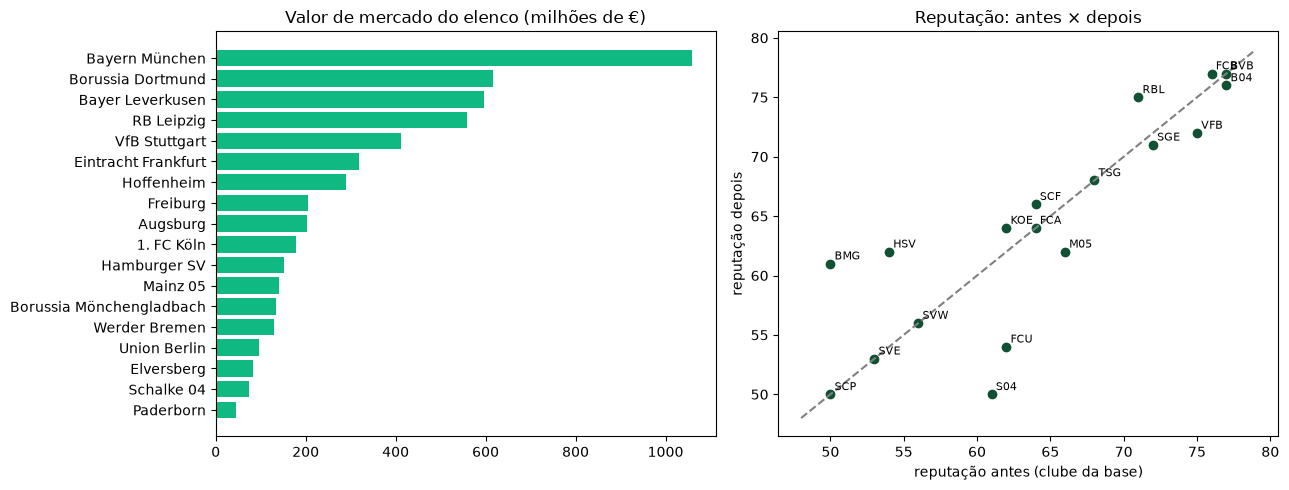

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(t['time_real'][::-1], t['valor_elenco_mi_eur'][::-1], color='#10b981'); ax[0].set_title('Valor de mercado do elenco (milhões de €)')
ax[1].scatter(t['reputacao_antes'], t['reputacao_depois'], color='#0f5132')
for _, r in t.iterrows(): ax[1].annotate(r['sigla'], (r['reputacao_antes'], r['reputacao_depois']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[1].plot([48, 79], [48, 79], '--', color='grey'); ax[1].set_xlabel('reputação antes (clube da base)'); ax[1].set_ylabel('reputação depois'); ax[1].set_title('Reputação: antes × depois')
plt.tight_layout(); plt.show()

## 3. Elencos por clube

In [5]:
el = jogadores[jogadores['situacao'] != 'liberado']
tab = pd.crosstab(el['time_real'], el['situacao'], margins=True, margins_name='total').sort_values('total', ascending=False)
display(tab)
print('Posições principais no jogo (todos os jogadores importados):')
display(el['posicao'].value_counts().rename('jogadores').to_frame().T)

situacao,atualizado,criado,total
time_real,,,
total,260,275,535
Schalke 04,4,31,35
Borussia Dortmund,17,17,34
Paderborn,2,31,33
Werder Bremen,15,17,32
1. FC Köln,16,16,32
Augsburg,15,16,31
Bayer Leverkusen,19,12,31
Borussia Mönchengladbach,16,15,31


Posições principais no jogo (todos os jogadores importados):


posicao,CB,CF,GK,DM,CM,AM,RW,LB,LW,RB,LWB,RWB,RM,LM
jogadores,112,83,61,53,45,45,26,25,25,23,13,13,6,5


## 4. Força estimada dos jogadores novos

A extração não traz atributos de jogo. A força (escala 1–20, a mesma da tela) dos jogadores **criados** foi estimada por uma regressão ajustada nos jogadores que já existiam no pacote (força calculada pelos atributos deles):

força ≈ a + b·ln(valor de mercado) + c·(idade − 26) + d·(idade − 26)² + e·goleiro

O potencial dos novos é a força mais 0,7 ponto por ano abaixo de 24 anos (no máximo 20). O jogo gera os atributos coerentes com a posição.

In [6]:
coef = pd.DataFrame({'variável': regressao['variaveis'], 'coeficiente': np.round(regressao['coeficientes'], 4)})
display(coef)
print(f"amostra: {regressao['amostra']} jogadores · erro médio (RMSE): {regressao['rmse_forca_1a20']:.2f} ponto na escala 1–20 · data de referência: {regressao['data_referencia']}")

,variável,coeficiente
0,constante,-2.0382
1,ln(valor de mercado),1.0696
2,idade − 26,0.3033
3,(idade − 26)²,-0.0130
4,goleiro,-1.6740


amostra: 259 jogadores · erro médio (RMSE): 1.05 ponto na escala 1–20 · data de referência: 2026-07-01


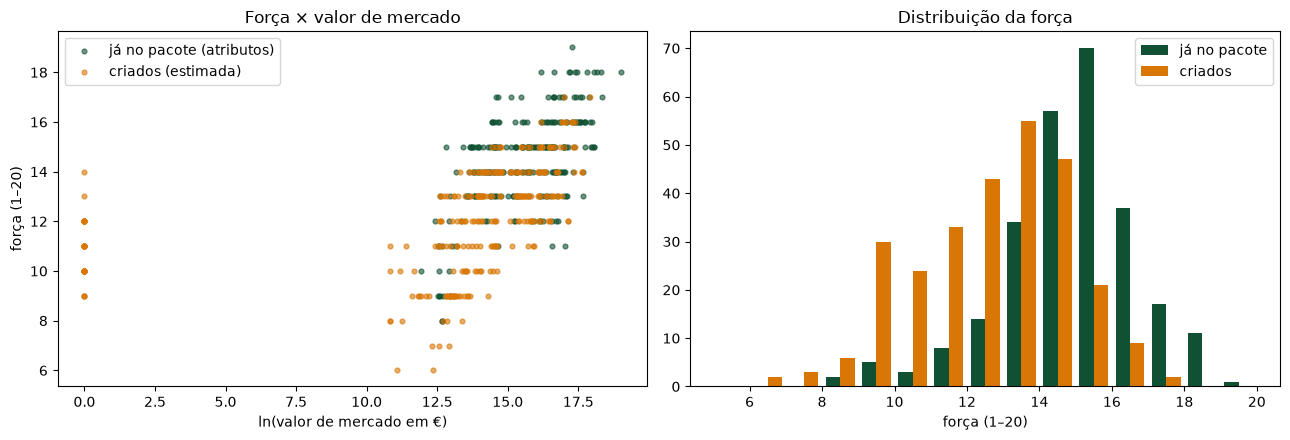

In [7]:
at = jogadores[(jogadores['situacao'] == 'atualizado') & (jogadores['valor_mercado_eur'] > 0)]
cr = jogadores[jogadores['situacao'] == 'criado']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(np.log(at['valor_mercado_eur']), at['forca'], s=12, alpha=.6, label='já no pacote (atributos)', color='#0f5132')
ax[0].scatter(np.log(cr['valor_mercado_eur'].clip(lower=1)), cr['forca'], s=12, alpha=.6, label='criados (estimada)', color='#d97706')
ax[0].set_xlabel('ln(valor de mercado em €)'); ax[0].set_ylabel('força (1–20)'); ax[0].legend(); ax[0].set_title('Força × valor de mercado')
ax[1].hist([at['forca'], cr['forca']], bins=range(5, 21), label=['já no pacote', 'criados'], color=['#0f5132', '#d97706'])
ax[1].set_xlabel('força (1–20)'); ax[1].legend(); ax[1].set_title('Distribuição da força')
plt.tight_layout(); plt.show()

In [8]:
print('Jogadores criados mais valiosos:')
display(cr.sort_values('valor_mercado_eur', ascending=False)[['nome', 'time_real', 'posicao', 'idade', 'valor_mercado_eur', 'forca', 'potencial']].head(20).reset_index(drop=True))

Jogadores criados mais valiosos:


,nome,time_real,posicao,idade,valor_mercado_eur,forca,potencial
0,Ismael Saibari,Bayern München,AM,25,59791439.0,17,17.0
1,Ethan Nwaneri,Borussia Dortmund,AM,19,45490587.0,14,18.0
2,Konstantinos Karetsas,Borussia Dortmund,RW,18,44938122.0,14,18.0
3,Afonso Moreira,Bayer Leverkusen,LW,21,35438595.0,15,17.0
4,Guéla Doué,Bayer Leverkusen,RB,23,34960784.0,16,17.0
5,Joane Gadou,Borussia Dortmund,CB,19,34199665.0,14,18.0
6,Brajan Gruda,RB Leipzig,RW,22,33356166.0,15,16.0
7,Rômulo,RB Leipzig,CF,24,33209430.0,16,16.0
8,Maxime Estève,RB Leipzig,CB,24,32330199.0,16,16.0
9,Neil El Aynaoui,RB Leipzig,DM,24,31880690.0,16,16.0


## 5. Jogadores liberados

Estavam no pacote em clubes da Bundesliga 2025/26 e não estão nos elencos de 2026/27 — agora sem clube, disponíveis no mercado.

In [9]:
lib = jogadores[jogadores['situacao'] == 'liberado']
display(lib.groupby('clube_jogo_nome_base').size().rename('liberados').sort_values(ascending=False).to_frame())
display(lib[['nome', 'clube_jogo_nome_base', 'posicao', 'idade', 'forca']].sort_values('forca', ascending=False).head(20).reset_index(drop=True))

,liberados
clube_jogo_nome_base,
VfB Wasserburg-Nord,24
TSV Talheim,21
SC Silberau,20
Lindenhof 04,13
Grünwalde 04,11
Bergheim am See 04,11
SV Wasserburg-Nord,11
Rabenfurt 04,10
SV Sonnenberg,9


,nome,clube_jogo_nome_base,posicao,idade,forca
0,Leon Goretzka,FC Reichenstein,CM,31,17
1,Alejandro Grimaldo,Steinkirchen 04,LWB,30,17
2,Julian Brandt,TSV Wasserburg-Nord,AM,30,17
3,Karim Adeyemi,TSV Wasserburg-Nord,LW,24,17
4,Arthur Theate,Grünwalde 04,CB,26,17
5,Exequiel Palacios,Steinkirchen 04,CM,27,16
6,Xaver Schlager,SV Sonnenberg,DM,28,16
7,Hugo Larsson,Grünwalde 04,DM,22,16
8,Niklas Süle,TSV Wasserburg-Nord,CB,30,16
9,Pascal Groß,TSV Wasserburg-Nord,CM,35,16


## 6. Fotos, escudos, técnicos e avisos

As imagens foram gravadas no pacote no padrão do jogo: `images/players/<id do jogador>.png`, `images/clubs/<id do clube>.png`, `images/coaches/<id do técnico>.png` e `images/leagues/ger-1.png`.

In [10]:
imgs = {k: len(os.listdir(os.path.join(PACOTE, 'images', k))) for k in ['players', 'clubs', 'coaches', 'leagues']}
display(pd.Series(imgs, name='imagens no pacote').to_frame().T)
print('Jogadores importados sem foto na extração:')
display(el[el['foto'] == 'não'][['nome', 'time_real', 'jogador_id']].reset_index(drop=True))
display(tecnicos)

,players,clubs,coaches,leagues
imagens no pacote,19524,826,644,44


Jogadores importados sem foto na extração:


,nome,time_real,jogador_id
0,Linus Guether,Union Berlin,linus-guether-2010
1,Gabriel Minutillo,Bayer Leverkusen,gabriel-minutillo-2010
2,Tom Wisbereit,Augsburg,tom-wisbereit-2007
3,Milo Adleff,Augsburg,milo-adleff-2008
4,Robert Draghici,Augsburg,robert-draghici-2008
5,Gil Neves,1. FC Köln,gil-neves-2008
6,Mads Broecker,Hamburger SV,mads-broecker-2008
7,Louis Lemke,Hamburger SV,louis-lemke-2009
8,Collin Etse,Eintracht Frankfurt,collin-etse-2005
9,Erblin Osmani,Bayern München,erblin-osmani-2009


,nome,time_real,clube_jogo_id,tecnico_id,foto
0,Miron Muslić,Schalke 04,tsv-talheim,tec-tsv-talheim,sim
1,Sebastian Hoeneß,VfB Stuttgart,vfb-kronach-west,tec-vfb-kronach-west,sim
2,Martín Demichelis,RB Leipzig,sv-sonnenberg,tec-sv-sonnenberg,sim
3,Mauro Lustrinelli,Union Berlin,sc-steinkirchen,tec-sc-steinkirchen,sim
4,Carles Martínez,Bayer Leverkusen,steinkirchen-04,tec-steinkirchen-04,sim
5,Christian Ilzer,Hoffenheim,bergheim-am-see-04,tec-bergheim-am-see-04,sim
6,Vincent Wagner,Elversberg,vfb-wasserburg-nord,tec-vfb-wasserburg-nord,sim
7,Julian Schuster,Freiburg,fc-grunwalde,tec-fc-grunwalde,sim
8,Manuel Baum,Augsburg,sv-wasserburg-nord,tec-sv-wasserburg-nord,sim
9,Ralf Kettemann,Paderborn,sc-silberau,tec-sc-silberau,sim


In [11]:
avisos = open(os.path.join(SAIDA, 'avisos.txt'), encoding='utf-8').read().strip().splitlines()
print(f'{len(avisos)} avisos (casamentos por critério mais fraco, para conferir):')
display(pd.DataFrame({'aviso': avisos}))

39 avisos (casamentos por critério mais fraco, para conferir):


,aviso
0,Chukwubuike Adamu: casado com Junior Adamu (me...
1,Finn Jeltsch: casado só pelo nome (nascimento ...
2,Andrija Maksimović: casado só pelo nome (nasci...
3,Tidiam Gomis: casado só pelo nome (nascimento ...
4,Carl Klaus: casado só pelo nome (nascimento 19...
5,Livan Burcu: casado só pelo nome (nascimento 2...
6,Marin Ljubičić: casado só pelo nome (nasciment...
7,Equi Fernández: casado com Ezequiel Fernández ...
8,Victor Okoh Boniface: casado com Victor Bonifa...
9,Christian Kofane: casado só pelo nome (nascime...


## 7. Conferência do pacote gravado

In [12]:
pl = pd.DataFrame(json.load(open(os.path.join(PACOTE, 'players.json'), encoding='utf-8')))
cl = pd.DataFrame(json.load(open(os.path.join(PACOTE, 'clubs.json'), encoding='utf-8')))
print(f"players.json: {len(pl)} jogadores ({pl['club'].isna().sum()} sem clube) · clubs.json: {len(cl)} clubes")
ids_ok = set(el['jogador_id']) <= set(pl['id'])
clube_ok = (pl.set_index('id').loc[el['jogador_id'], 'club'].values == el['clube_jogo_id'].values).all()
print('Todo jogador da extração está no pacote:', ids_ok, '· no clube certo:', bool(clube_ok))
display(cl)

players.json: 26466 jogadores (487 sem clube) · clubs.json: 856 clubes
Todo jogador da extração está no pacote: True · no clube certo: True


,id,name,shortName,reputation,country,league,city,balance,fans,facilities,state,stateDivision
0,tsv-talheim,Schalke 04,S04,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,vfb-kronach-west,VfB Stuttgart,VFB,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sv-sonnenberg,RB Leipzig,RBL,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,sc-steinkirchen,Union Berlin,FCU,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,steinkirchen-04,Bayer Leverkusen,B04,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
851,academia-maracay-nueva,Deportivo La Guaira,GUA,40,ven,ven-1,Caracas,3417000.0,155567.0,"{'training': 7, 'youth': 8, 'medical': 5, 'sta...",NaN,NaN
852,academia-san-felipe-viejo,Portuguesa FC,POR,38,ven,ven-1,Acarigua-Araure,3055000.0,142050.0,"{'training': 6, 'youth': 5, 'medical': 8, 'sta...",NaN,NaN
853,estudiantes-de-guanare-alto,Rayo Zuliano,RAY,36,ven,ven-1,Maracaibo,2989000.0,131453.0,"{'training': 5, 'youth': 3, 'medical': 7, 'sta...",NaN,NaN
854,club-puerto-ordaz-sur,Deportivo Táchira,TAC,39,ven,ven-1,San Cristóbal,2750000.0,136532.0,"{'training': 7, 'youth': 6, 'medical': 6, 'sta...",NaN,NaN


# Parte 2 — 2. Bundesliga, 3. Liga e as quatro divisões inglesas

Script `scripts/importar-ligas.ts`. Fontes: as **planilhas editadas** (formato do editor, com atributos completos) em `D:\DATA BASE FOOTERA\csv_editor_ger` e `csv_editor_eng`, e a **extração futmob 2026/27** das seis ligas.

Decisões do usuário: as planilhas mandam e cada clube é completado com os jogadores da extração que faltam (força estimada); os 12 clubes ingleses que a base não tinha foram **criados** (Championship, League One e League Two com 24 clubes, como na realidade); quando um jogador aparecia duas vezes (livre no pacote e de novo numa planilha), ficou o da planilha e o registro antigo foi removido.

In [13]:
SAIDA2 = r'D:\DATA BASE FOOTERA\importacao-2026-27'
ler2 = lambda nome: pd.read_csv(os.path.join(SAIDA2, nome), sep=';', encoding='utf-8-sig')
jog2, clu2, tec2, rem2 = ler2('jogadores.csv'), ler2('clubes.csv'), ler2('tecnicos.csv'), ler2('removidos.csv')
reg2 = json.load(open(os.path.join(SAIDA2, 'regressao.json'), encoding='utf-8'))
print(f'{len(jog2)} linhas de jogadores, {len(clu2)} clubes, {len(tec2)} técnicos com foto/casamento, {len(rem2)} registros removidos')

3920 linhas de jogadores, 130 clubes, 128 técnicos com foto/casamento, 57 registros removidos


## 2.1 Resumo por liga

- **planilha**: jogador da planilha que casou com a extração (fica com os atributos da planilha e a foto da extração).
- **só na planilha**: está na planilha mas não no elenco real extraído (mantido, sem foto).
- **extração (existente)**: estava no universo (ex.: livre no pacote) e foi para o clube real.
- **extração (novo)**: criado com força estimada.
- **fora**: sem data de nascimento na extração (o jogo exige a data; não importado).

In [14]:
display(pd.crosstab(jog2['liga'], jog2['situacao'].fillna('fora'), margins=True, margins_name='total'))

situacao,extração (existente),extração (novo),fora,planilha,só na planilha,total
liga,,,,,,
eng-1,1,79,0,464,32,576
eng-2,1,180,0,464,38,683
eng-3,0,185,6,478,25,694
eng-4,0,180,10,468,30,688
ger-2,2,126,1,423,26,578
ger-3,1,198,2,479,21,701
total,5,948,19,2776,172,3920


## 2.2 Clubes

Clube real → clube do jogo. Os clubes **criados** receberam a reputação do clube da planilha com valor de elenco mais parecido.

In [15]:
c2 = clu2.copy(); c2['valor_elenco_mi_eur'] = (c2['valor_elenco_eur'] / 1e6).round(1)
display(c2[['liga', 'time_real', 'clube_jogo_id', 'situacao', 'reputacao', 'valor_elenco_mi_eur', 'escudo']])

,liga,time_real,clube_jogo_id,situacao,reputacao,valor_elenco_mi_eur,escudo
0,ger-2,Holstein Kiel,altenbruck-04,planilha,37,27.3,sim
1,ger-2,St. Pauli,sv-lindenhof,planilha,50,24.9,sim
2,ger-2,1. FC Nürnberg,eintracht-kronach-west,planilha,51,59.9,sim
3,ger-2,Hertha BSC,eintracht-talheim,planilha,53,28.8,sim
4,ger-2,Magdeburg,eintracht-muhlhausen-ost,planilha,35,25.2,sim
...,...,...,...,...,...,...,...
125,eng-4,Swindon Town,carlow-heath-albion,planilha,10,4.3,sim
126,eng-4,Port Vale,ashford-united,planilha,6,4.9,sim
127,eng-4,Exeter City,ravenscar-wanderers,planilha,5,3.5,sim
128,eng-4,Shrewsbury Town,ironbridge-united,planilha,5,4.9,sim


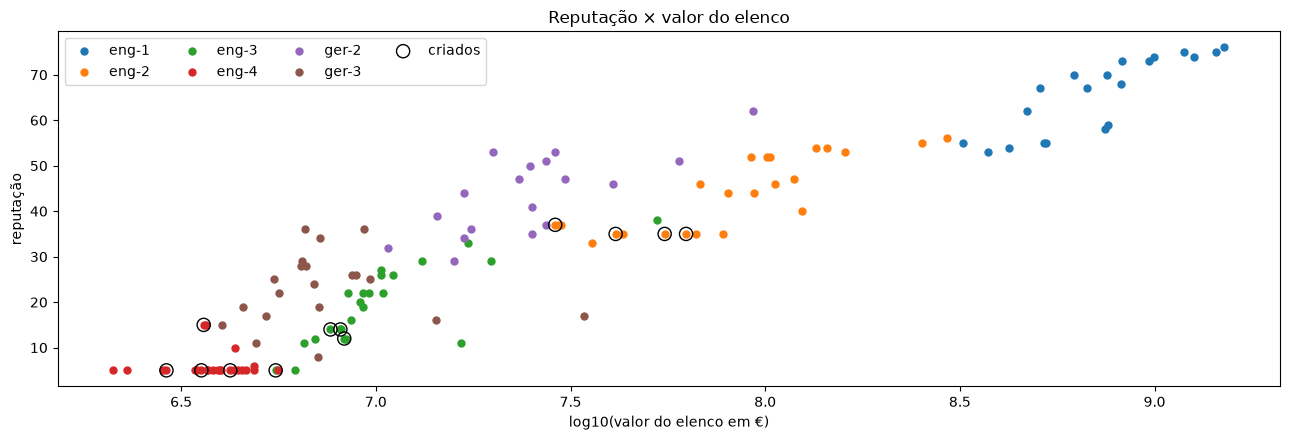

In [16]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for lg, g in c2.groupby('liga'): ax.scatter(np.log10(g['valor_elenco_eur'].clip(lower=1)), g['reputacao'], label=lg, s=25)
cr2 = c2[c2['situacao'] == 'criado']; ax.scatter(np.log10(cr2['valor_elenco_eur']), cr2['reputacao'], facecolors='none', edgecolors='black', s=90, label='criados')
ax.set_xlabel('log10(valor do elenco em €)'); ax.set_ylabel('reputação'); ax.legend(ncol=4); ax.set_title('Reputação × valor do elenco'); plt.tight_layout(); plt.show()

## 2.3 Força

A força (1–20) dos jogadores **criados** saiu de uma regressão ajustada nos jogadores que têm atributos (planilhas e pacote):

In [17]:
display(pd.DataFrame({'variável': reg2['variaveis'], 'coeficiente': np.round(reg2['coeficientes'], 4)}))
print(f"amostra: {reg2['amostra']} jogadores · erro médio (RMSE): {reg2['rmse_forca_1a20']:.2f} ponto")
display(jog2.groupby(['liga', 'forca_origem'])['forca'].agg(['count', 'mean', 'min', 'max']).round(1))

,variável,coeficiente
0,constante,-2.8866
1,ln(valor de mercado),1.0487
2,idade − 26,0.2573
3,(idade − 26)²,-0.0131
4,goleiro,-1.1048


amostra: 2607 jogadores · erro médio (RMSE): 1.34 ponto


count  mean   min   max
liga  forca_origem                         
eng-1 atributos       497  14.6  10.0  20.0
      estimada         79  12.6   7.0  17.0
eng-2 atributos       503  11.5   6.0  16.0
      estimada        180  11.1   6.0  14.0
eng-3 atributos       503   9.4   5.0  13.0
      estimada        185   9.2   6.0  12.0
eng-4 atributos       498   8.2   4.0  12.0
      estimada        180   9.0   6.0  12.0
ger-2 atributos       451  11.7   6.0  17.0
      estimada        126   9.1   7.0  13.0
ger-3 atributos       501   9.4   5.0  15.0
      estimada        198   9.1   7.0  14.0

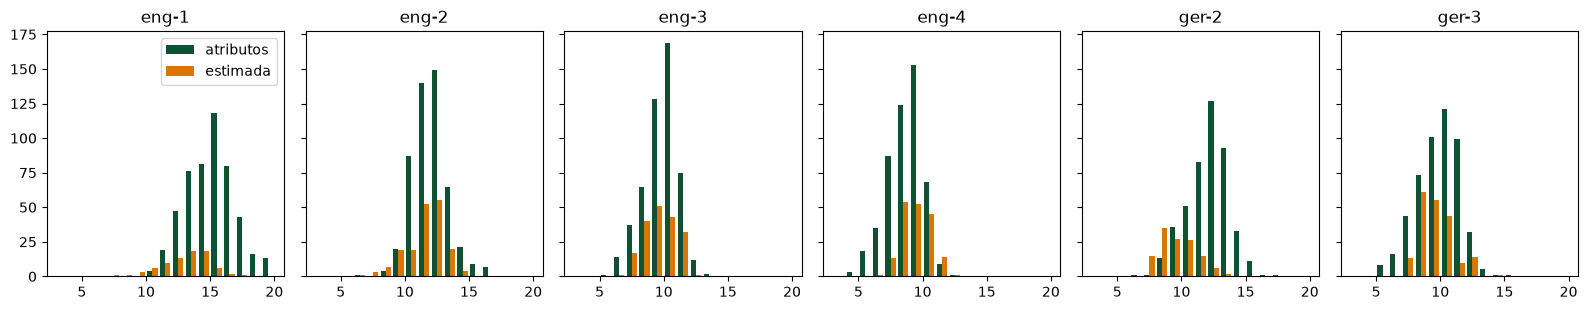

In [18]:
fig, ax = plt.subplots(1, 6, figsize=(16, 3.2), sharey=True)
for i, (lg, g) in enumerate(jog2.dropna(subset=['forca']).groupby('liga')):
    ax[i].hist([g[g.forca_origem == 'atributos']['forca'], g[g.forca_origem == 'estimada']['forca']], bins=range(3, 21), label=['atributos', 'estimada'], color=['#0f5132', '#d97706'])
    ax[i].set_title(lg)
ax[0].legend(); plt.tight_layout(); plt.show()

## 2.4 Duplicatas removidas, técnicos e avisos

In [19]:
display(rem2)
display(tec2)
av2 = open(os.path.join(SAIDA2, 'avisos.txt'), encoding='utf-8').read().strip().splitlines()
print(f'{len(av2)} avisos'); display(pd.DataFrame({'aviso': av2}))

,jogador_id,nome,na_base
0,nico-richter-2003,Pavao Pervan,sim
1,felix-wolf-2001,Hauke Wahl,sim
2,sebastian-hartmann-2006,Joakim Mæhle,sim
3,leroy-werner-1994,Kilian Fischer,sim
4,julian-schmidt-2006,Saël Kumbedi,sim
5,lukas-schulz-1992,Yannick Gerhardt,sim
6,marco-zimmermann-2002,Elvis Rexhbeçaj,sim
7,nico-braun-2005,Muhammed Damar,sim
8,jan-schroder-2003,Maximilian Arnold,sim
9,dennis-krause-2006,Mattias Svanberg,sim


,liga,tecnico,time_real,tecnico_id,clube_jogo_id,foto
0,ger-2,Tim Walter,Holstein Kiel,tec-altenbruck-04,altenbruck-04,sim
1,ger-2,Marcel Rapp,St. Pauli,tec-sv-lindenhof,sv-lindenhof,sim
2,ger-2,Miroslav Klose,1. FC Nürnberg,tec-eintracht-kronach-west,eintracht-kronach-west,sim
3,ger-2,Stefan Leitl,Hertha BSC,tec-eintracht-talheim,eintracht-talheim,sim
4,ger-2,Petrik Sander,Magdeburg,tec-eintracht-muhlhausen-ost,eintracht-muhlhausen-ost,sim
...,...,...,...,...,...,...
123,eng-4,Ian Holloway,Swindon Town,tec-carlow-heath-albion,carlow-heath-albion,sim
124,eng-4,Jon Brady,Port Vale,tec-ashford-united,ashford-united,sim
125,eng-4,Matt Taylor,Exeter City,tec-ravenscar-wanderers,ravenscar-wanderers,sim
126,eng-4,Gavin Cowan,Shrewsbury Town,tec-ironbridge-united,ironbridge-united,sim


106 avisos


,aviso
0,técnico Mersad Selimbegović (Alemannia Aachen)...
1,Pavao Pervan: registro antigo nico-richter-200...
2,Hauke Wahl: registro antigo felix-wolf-2001 re...
3,Joakim Mæhle: registro antigo sebastian-hartma...
4,Kilian Fischer: registro antigo leroy-werner-1...
...,...
101,Maxim Safronov: TSV Havelse passou de 40 jogad...
102,Marco Schleef: TSV Havelse passou de 40 jogado...
103,Yannik Jaeschke: TSV Havelse passou de 40 joga...
104,Tim Dierßen: TSV Havelse passou de 40 jogadore...


## 2.5 Conferência do pacote gravado

In [20]:
pl2 = pd.DataFrame(json.load(open(os.path.join(PACOTE, 'players.json'), encoding='utf-8')))
imgs2 = {k: len(os.listdir(os.path.join(PACOTE, 'images', k))) for k in ['players', 'clubs', 'coaches', 'leagues']}
print(f"players.json: {len(pl2)} registros ({int(pl2['$remove'].fillna(False).sum()) if '$remove' in pl2 else 0} remoções) · imagens: {imgs2}")
ok = jog2.dropna(subset=['jogador_id'])
print('Todo jogador importado está no pacote ou na base:', bool(set(ok[ok.situacao != 'só na planilha']['jogador_id']) <= set(pl2['id'])))

players.json: 26466 registros (101 remoções) · imagens: {'players': 19524, 'clubs': 826, 'coaches': 644, 'leagues': 44}
Todo jogador importado está no pacote ou na base: True


# Parte 3 — 22 países (36 divisões)

Script `scripts/importar-paises.ts`. Fontes: as **planilhas reais** de `D:\DATA BASE FOOTERA\csv_jogadores` (formato do editor, ids da base, nomes e atributos montados por outro agente a partir da extração) e a **extração futmob** de cada liga (fotos, escudos, técnicos, logos e os jogadores que faltam nos elencos de 25 das planilhas).

Divisões: Brasil (Séries B, C e D), Espanha (1ª–3ª), Itália, França, Portugal, Holanda, Argentina, Bélgica, Japão, Áustria, México, Irlanda e Rússia (1ª–2ª); Croácia, Uruguai, Colômbia, Equador, Paraguai, Chile, Peru, Bolívia e Venezuela (1ª). A Inglaterra já tinha entrado na Parte 2 (as planilhas inglesas de `csv_jogadores` são as mesmas).

Regras (as mesmas da Parte 2):
- a planilha manda; jogador da planilha que a extração põe noutro clube do jogo vai para o clube da extração;
- cada clube é completado com os jogadores da extração que faltam, com força estimada por uma regressão **por liga**;
- elenco máximo de 40: saem primeiro os acrescentados da extração de menor valor; goleiros não saem (o jogo exige 2);
- duplicata: fica o da planilha e o registro antigo é removido, salvo se o antigo está num clube fora desta importação (Alemanha, Inglaterra, Série A);
- times casados **só por nome igual** (a semelhança de nome casava clubes fictícios com times reais, ex.: "Real Robledal" × "Real Jaén");
- o jogo aceita 15 a 45 anos na data de início; datas "0001-01-01" da extração contam como ausentes.

In [21]:
SAIDA3 = r'D:\DATA BASE FOOTERA\importacao-paises-2026-27'
ler3 = lambda nome: pd.read_csv(os.path.join(SAIDA3, nome), sep=';', encoding='utf-8-sig')
jog3, clu3, tec3, rem3 = ler3('jogadores.csv'), ler3('clubes.csv'), ler3('tecnicos.csv'), ler3('removidos.csv')
reg3 = json.load(open(os.path.join(SAIDA3, 'regressao.json'), encoding='utf-8'))
jog3['pais'] = jog3['liga_extracao'].str[:3]
print(f'{len(jog3)} linhas de jogadores, {len(clu3)} times casados, {len(tec3)} técnicos casados, {len(rem3)} registros removidos')

22326 linhas de jogadores, 678 times casados, 583 técnicos casados, 44 registros removidos


## 3.1 Resumo por liga

- **planilha**: casou com a extração (atributos da planilha, foto da extração).
- **só na planilha**: não está nos elencos extraídos (mantido, sem foto) — inclui os clubes que seguem fictícios (3ª espanhola, 2ª irlandesa) e as ligas cuja extração veio sem jogadores (Uruguai, J2 League).
- **extração (novo)**: criado com força estimada. **fora**: sem data de nascimento ou fora da faixa de idade.
- **time fora do jogo**: o time real não tem clube no jogo (ex.: a Liga Profesional argentina tem 30 times e o jogo 20; a 2ª argentina, 36).

In [22]:
display(pd.crosstab(jog3['liga_extracao'], jog3['situacao'].fillna('fora'), margins=True, margins_name='total'))

situacao,extração (novo),fora,planilha,só na planilha,time fora do jogo,total
liga_extracao,,,,,,
arg-1,367,2,755,0,0,1124
arg-2,87,2,262,0,303,654
aut-1,39,0,298,0,0,337
aut-2,68,0,402,0,0,470
bel-1,93,0,483,0,0,576
bel-2,59,1,312,0,27,399
bol-1,203,2,398,0,0,603
bra-2,392,0,512,0,0,904
bra-3,81,0,471,27,0,579


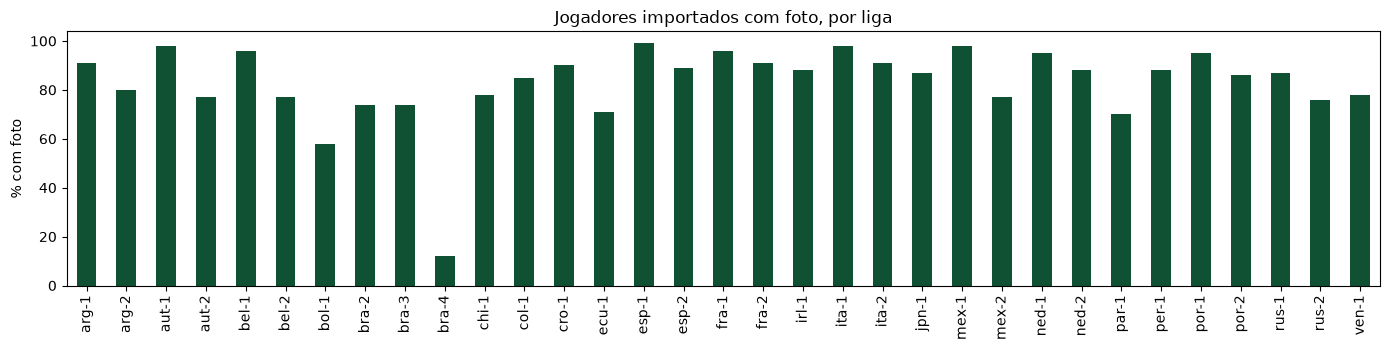

In [23]:
fotos = jog3[jog3.situacao.isin(['planilha', 'extração (novo)', 'extração (existente)'])].groupby('liga_extracao')['foto'].apply(lambda s: (s == 'sim').mean() * 100).round(0)
fig, ax = plt.subplots(figsize=(14, 3.6)); fotos.plot.bar(ax=ax, color='#0f5132'); ax.set_ylabel('% com foto'); ax.set_xlabel('')
ax.set_title('Jogadores importados com foto, por liga'); plt.tight_layout(); plt.show()

## 3.2 Clubes

Time real → clube do jogo (pelo nome igual ao da planilha). Um time pode estar noutra divisão do mesmo país na planilha.

In [24]:
c3 = clu3.copy(); c3['valor_elenco_mi_eur'] = (c3['valor_elenco_eur'] / 1e6).round(1)
display(c3.groupby('liga_no_jogo').agg(clubes=('clube_jogo_id', 'count'), escudos=('escudo', lambda s: (s == 'sim').sum()), reputacao_media=('reputacao', 'mean'), valor_medio_mi=('valor_elenco_mi_eur', 'mean')).round(1))

,clubes,escudos,reputacao_media,valor_medio_mi
liga_no_jogo,,,,
arg-1,20,20,58.1,40.9
arg-2,20,20,35.5,11.4
aut-1,12,12,50.4,28.2
aut-2,16,16,29.8,5.6
bel-1,16,16,53.5,71.2
bel-2,16,16,32.2,12.9
bol-1,16,16,43.7,4.2
bra-2,20,20,44.4,9.6
bra-3,20,20,21.0,1.6


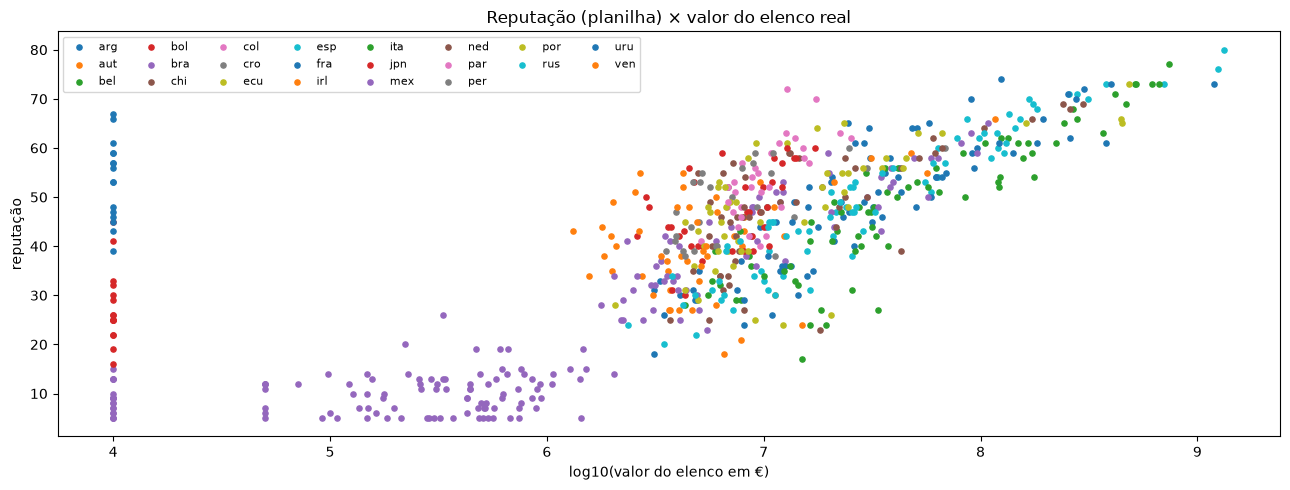

In [25]:
fig, ax = plt.subplots(figsize=(13, 5))
for p, g in c3.assign(pais=c3['liga_no_jogo'].str[:3]).groupby('pais'): ax.scatter(np.log10(g['valor_elenco_eur'].clip(lower=1e4)), g['reputacao'], label=p, s=14)
ax.set_xlabel('log10(valor do elenco em €)'); ax.set_ylabel('reputação'); ax.legend(ncol=8, fontsize=8); ax.set_title('Reputação (planilha) × valor do elenco real'); plt.tight_layout(); plt.show()

## 3.3 Força dos jogadores criados

Regressão de força (1–20) em ln(valor de mercado), idade, idade² e goleiro, ajustada **por liga** nos jogadores da planilha que casaram com a extração (com 60 ou mais na amostra; senão, a regressão geral). O erro é baixo porque os atributos das planilhas já foram derivados do valor de mercado.

In [26]:
rl = pd.DataFrame(reg3['ligas']).T[['modelo', 'amostra', 'rmse_forca_1a20', 'criados']]; rl['rmse_forca_1a20'] = rl['rmse_forca_1a20'].astype(float).round(2)
print(f"regressão geral: {reg3['geral']['amostra']} jogadores, RMSE {reg3['geral']['rmse_forca_1a20']:.2f}"); display(rl)
display(jog3.dropna(subset=['forca']).groupby(['liga_extracao', 'forca_origem'])['forca'].agg(['count', 'mean', 'min', 'max']).round(1).unstack())

regressão geral: 11877 jogadores, RMSE 0.42


,modelo,amostra,rmse_forca_1a20,criados
bra-2,da liga,415,0.40,260
bra-3,da liga,173,0.34,73
bra-4,da liga,265,0.32,180
esp-1,da liga,474,0.56,38
esp-2,da liga,438,0.43,122
esp-3,geral,37,0.42,10
ita-1,da liga,488,0.44,110
ita-2,da liga,482,0.39,141
fra-1,da liga,410,0.46,58
fra-2,da liga,386,0.38,82


count               mean                min                max         
forca_origem  atributos estimada atributos estimada atributos estimada atributos estimada
liga_extracao                                                                            
arg-1             755.0    367.0       9.9      7.1       6.0      4.0      14.0     11.0
arg-2             262.0     87.0       8.7      6.6       5.0      5.0      11.0     10.0
aut-1             298.0     39.0       8.7      6.6       5.0      5.0      13.0      9.0
aut-2             402.0     68.0       6.9      5.2       4.0      4.0      10.0      7.0
bel-1             483.0     93.0       9.5      7.4       5.0      6.0      14.0     10.0
bel-2             312.0     59.0       7.7      7.5       5.0      5.0      10.0     10.0
bol-1             398.0    203.0       8.4      5.7       4.0      4.0      12.0      9.0
bra-2             512.0    392.0       9.2      6.1       6.0      4.0      12.0     10.0
bra-3             498.0     81.0       7.5      5.7       4.0      4.0      11.0      9.0
bra-4            2395.0    200.0       7.1      5.7       4.0      3.0      11.0      9.0
chi-1             397.0    186.0       8.6      5.9       5.0      4.0      12.0     11.0
col-1             500.0    159.0       9.1      6.5       5.0      5.0      12.0     11.0
cro-1             250.0     55.0       8.5      6.4       5.0      5.0      13.0      9.0
ecu-1             400.0    132.0       8.8      6.1       5.0      3.0      12.0     10.0
esp-1             490.0     38.0      11.7      8.2       7.0      6.0      19.0     12.0
esp-2             568.0    132.0       9.2      7.2       5.0      5.0      14.0     10.0
esp-3             437.0      NaN       8.1      NaN       2.0      NaN      14.0      NaN
fra-1             450.0     58.0      11.1      7.9       6.0      6.0      18.0     11.0
fra-2             450.0     82.0       8.8      6.6       6.0      5.0      12.0      8.0
irl-1             251.0     73.0       6.9      4.0       4.0      2.0      11.0      7.0
irl-2             249.0      NaN       8.2      NaN       2.0      NaN      13.0      NaN
ita-1             501.0    110.0      11.9      8.6       6.0      6.0      17.0     12.0
ita-2             499.0    141.0       9.4      6.9       6.0      5.0      12.0     10.0
jpn-1             521.0    192.0       9.1      7.0       5.0      4.0      12.0      9.0
jpn-2             379.0      NaN       8.2      NaN       5.0      NaN      11.0      NaN
mex-1             448.0     33.0      10.3      8.3       5.0      7.0      16.0     11.0
mex-2             455.0     66.0       7.9      6.2       4.0      4.0      12.0      8.0
ned-1             450.0     94.0       9.8      7.3       6.0      6.0      14.0     11.0
ned-2             453.0    251.0       7.7      5.9       4.0      4.0      12.0      9.0
par-1             302.0    126.0       9.2      6.9       6.0      4.0      13.0     10.0
per-1             444.0     57.0       8.6      6.2       5.0      4.0      11.0     10.0
por-1             451.0    104.0      10.0      7.8       7.0      6.0      15.0     11.0
por-2             451.0     92.0       8.2      6.9       5.0      5.0      11.0     10.0
rus-1             399.0    130.0      10.2      7.6       6.0      4.0      14.0     11.0
rus-2             450.0    136.0       8.5      6.6       6.0      5.0      11.0      9.0
uru-1             393.0      NaN       8.8      NaN       4.0      NaN      17.0      NaN
ven-1             344.0    107.0       8.2      5.9       4.0      4.0      11.0     10.0

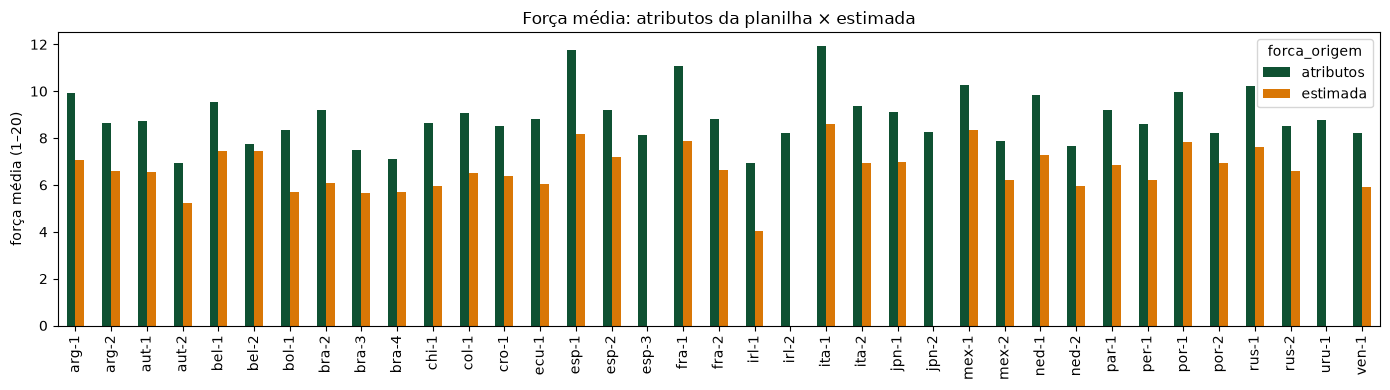

In [27]:
med = jog3.dropna(subset=['forca']).groupby(['liga_extracao', 'forca_origem'])['forca'].mean().unstack()
fig, ax = plt.subplots(figsize=(14, 4)); med.plot.bar(ax=ax, color=['#0f5132', '#d97706']); ax.set_ylabel('força média (1–20)'); ax.set_xlabel('')
ax.set_title('Força média: atributos da planilha × estimada'); plt.tight_layout(); plt.show()

## 3.4 Duplicatas removidas, técnicos e avisos

In [28]:
display(rem3)
print(f"técnicos com foto: {(tec3['foto'] == 'sim').sum()} de {len(tec3)}")
av3 = open(os.path.join(SAIDA3, 'avisos.txt'), encoding='utf-8').read().strip().splitlines()
tipo = pd.Series(av3).str.replace(r'^[^:]*: ', '', regex=True).str.replace(r'"[^"]*"', 'X', regex=True).str.replace(r'\d+', 'N', regex=True).str[:60]
print(f'{len(av3)} avisos'); display(tipo.value_counts().head(15).rename('quantidade').to_frame())
display(pd.DataFrame({'aviso': av3}))

,jogador_id,nome,na_base
0,takumi-suzuki-2001,Takumi Suzuki,sim
1,niklas-fischer-2002,Yan Diomande,sim
2,tim-muller-1999,Karim Adeyemi,sim
3,sebastian-werner-1999,Alejandro Grimaldo,sim
4,tim-hartmann-1999,Péter Gulácsi,sim
5,tim-werner-2002,Jeanuël Belocian,sim
6,paul-koch-1996,Ismaël Gharbi,sim
7,tobias-braun-1993,Benedikt Gimber,sim
8,paul-meyer-2001,Giorgi Gocholeishvili,sim
9,nico-klein-1994,Yan Couto,sim


técnicos com foto: 498 de 583
798 avisos


,quantidade
sem data de nascimento na extração; não importado,63
"N jogadores, acima de N; ficaram sem clube N acrescentado(s)",52
time X (extração esp-N) não está no jogo; jogadores dele não,40
time X (extração arg-N) não está no jogo; jogadores dele não,26
nascimento X inválido na planilha; mantido o da base (N-N-N),18
time X (extração irl-N) não está no jogo; jogadores dele não,10
"planilha em Club Brugge NXT, extração em Club Brugge → vai p",8
"planilha em Gent UN, extração em Gent → vai para Gent",8
"planilha em Tirol, extração em Rio Branco ES → vai para Rio",7
"planilha em Anderlecht Futures, extração em Anderlecht → vai",7


,aviso
0,"Kalliston Kalliston (bra-4): nascimento ""0001-..."
1,"José Sousa Santos (bra-4): nascimento ""0001-01..."
2,"Cauê Felippo Inacio (bra-4): nascimento ""0001-..."
3,"Renahn Ferreira de Souza (bra-4): nascimento ""..."
4,"Didi Didi (bra-4): nascimento ""0001-01-01"" inv..."
...,...
793,"GV San José: 42 jogadores, acima de 40; ficara..."
794,"ABB: 46 jogadores, acima de 40; ficaram sem cl..."
795,"Independiente Petrolero: 44 jogadores, acima d..."
796,"Blooming: 45 jogadores, acima de 40; ficaram s..."


## 3.5 Conferência do pacote gravado

In [29]:
pl3 = pd.DataFrame(json.load(open(os.path.join(PACOTE, 'players.json'), encoding='utf-8')))
imgs3 = {k: len(os.listdir(os.path.join(PACOTE, 'images', k))) for k in ['players', 'clubs', 'coaches', 'leagues']}
print(f"players.json: {len(pl3)} registros · imagens: {imgs3}")
imp = jog3[jog3.situacao.isin(['planilha', 'extração (novo)', 'extração (existente)'])]
print('Todo jogador importado está no pacote:', bool(set(imp['jogador_id']) <= set(pl3['id'])))
com_foto = imp[imp.foto == 'sim']['jogador_id']
arqs = {os.path.splitext(f)[0] for f in os.listdir(os.path.join(PACOTE, 'images', 'players'))}
print('Toda foto prevista está gravada:', bool(set(com_foto) <= arqs))

players.json: 26466 registros · imagens: {'players': 19524, 'clubs': 826, 'coaches': 644, 'leagues': 44}
Todo jogador importado está no pacote: True
Toda foto prevista está gravada: True
